# MiniVLA optimization results: precision, kernels, and compilation

A notebook-first reading of the actual RTX 3060 benchmark run.

The five configurations use one trained FP32 checkpoint, identical inputs, and the same architecture. Each latency result includes **20 warm-up iterations and 100 CUDA-event measurements**. Compilation and first-call costs are reported separately from steady state.

In [1]:
from pathlib import Path
import csv
import json
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
metrics_dir = ROOT / 'results' / 'metrics'

with (metrics_dir / 'benchmarks.csv').open(newline='', encoding='utf-8') as handle:
    rows = list(csv.DictReader(handle))
with (metrics_dir / 'benchmark_environment.json').open(encoding='utf-8') as handle:
    environment = json.load(handle)

rows = [row for row in rows if row['status'] == 'ok']
assert len(rows) == 15, f'Expected 15 successful benchmark rows, found {len(rows)}'
print(f"GPU: {environment['gpu_name']} | compute capability {environment['compute_capability']}")
print(f"PyTorch: {environment['pytorch_version']} | CUDA runtime: {environment['cuda_runtime']}")
print(f"BF16 supported: {environment['bf16_supported']} | Successful rows: {len(rows)}/15")

GPU: NVIDIA GeForce RTX 3060 | compute capability 8.6
PyTorch: 2.11.0+cu128 | CUDA runtime: 12.8
BF16 supported: True | Successful rows: 15/15


## Experiment matrix

| ID | Precision | Attention | Compilation |
|---|---|---|---|
| A | FP32 | Reference | Off |
| B | FP16 autocast | Reference | Off |
| C | BF16 autocast | Reference | Off |
| D | BF16 autocast | PyTorch SDPA | Off |
| E | BF16 autocast | PyTorch SDPA | On |

SDPA used PyTorch automatic dispatch. Flash, memory-efficient, and math backends were enabled, but the selected backend was not independently verified—so this project does not claim that FlashAttention ran.

In [2]:
batch32 = {row['configuration']: row for row in rows if int(row['batch_size']) == 32}
print(f"{'config':<8} {'precision':<10} {'attention':<11} {'compiled':<9} {'median ms':>11} {'p95 ms':>10} {'samples/s':>12}")
for name in 'ABCDE':
    row = batch32[name]
    print(f"{name:<8} {row['precision']:<10} {row['attention']:<11} {row['compiled']:<9} "
          f"{float(row['median_latency_ms']):>11.3f} {float(row['p95_latency_ms']):>10.3f} "
          f"{float(row['throughput_samples_s']):>12,.0f}")

config   precision  attention   compiled    median ms     p95 ms    samples/s
A        fp32       reference   False           1.610      2.065       18,992
B        fp16       reference   False           2.171      3.091       13,842
C        bf16       reference   False           2.282      2.864       13,490
D        bf16       sdpa        False           2.008      2.686       14,782
E        bf16       sdpa        True            1.756      2.255       17,167


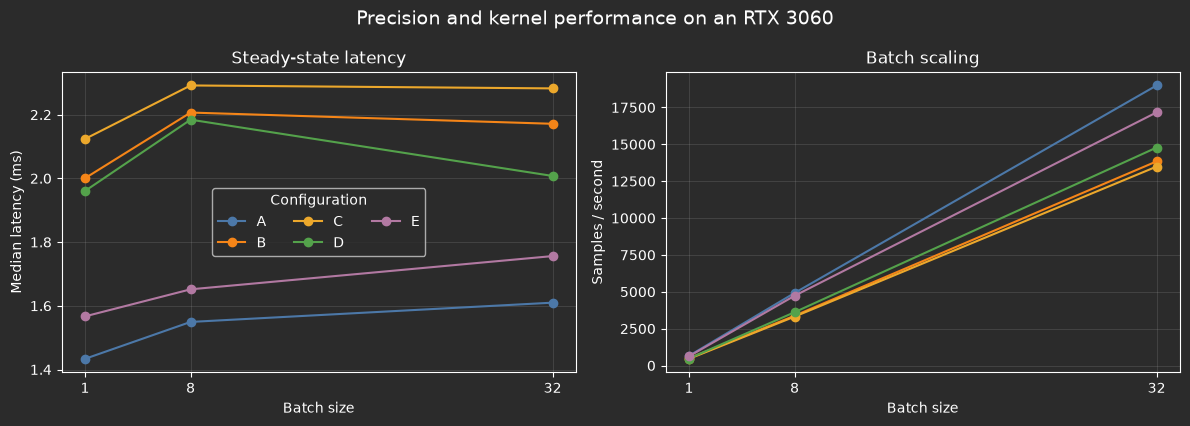

In [3]:
colors = {'A': '#4C78A8', 'B': '#F58518', 'C': '#ECA82C', 'D': '#54A24B', 'E': '#B279A2'}
figure, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for configuration in 'ABCDE':
    selected = sorted((row for row in rows if row['configuration'] == configuration), key=lambda row: int(row['batch_size']))
    batches = [int(row['batch_size']) for row in selected]
    axes[0].plot(batches, [float(row['median_latency_ms']) for row in selected], marker='o',
                 label=configuration, color=colors[configuration])
    axes[1].plot(batches, [float(row['throughput_samples_s']) for row in selected], marker='o',
                 label=configuration, color=colors[configuration])
axes[0].set(title='Steady-state latency', xlabel='Batch size', ylabel='Median latency (ms)')
axes[1].set(title='Batch scaling', xlabel='Batch size', ylabel='Samples / second')
for axis in axes:
    axis.set_xticks([1, 8, 32])
    axis.grid(alpha=0.25)
axes[0].legend(title='Configuration', ncol=3)
figure.suptitle('Precision and kernel performance on an RTX 3060', fontsize=14)
figure.tight_layout()
plt.show()

## Precision is not automatically faster

This model is tiny: launch overhead and autocast conversions matter more than tensor-core arithmetic. The result is a useful counterexample to the assumption that lower precision always improves latency. Numerical drift and memory must be considered alongside speed.

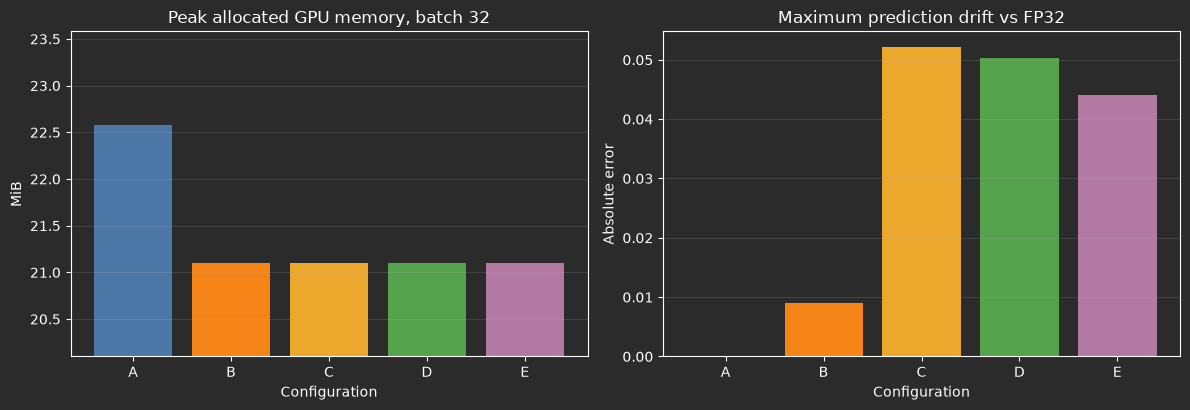

A: peak=22.58 MiB, mean drift=0.00000, max drift=0.00000
B: peak=21.10 MiB, mean drift=0.00041, max drift=0.00899
C: peak=21.10 MiB, mean drift=0.00263, max drift=0.05219
D: peak=21.10 MiB, mean drift=0.00265, max drift=0.05023
E: peak=21.10 MiB, mean drift=0.00341, max drift=0.04408


In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = list('ABCDE')
peak_memory = [float(batch32[name]['peak_allocated_mb']) for name in labels]
max_error = [float(batch32[name]['numerical_max_abs_vs_fp32']) for name in labels]
axes[0].bar(labels, peak_memory, color=[colors[name] for name in labels])
axes[0].set(title='Peak allocated GPU memory, batch 32', xlabel='Configuration', ylabel='MiB')
axes[0].set_ylim(min(peak_memory) - 1, max(peak_memory) + 1)
axes[1].bar(labels, max_error, color=[colors[name] for name in labels])
axes[1].set(title='Maximum prediction drift vs FP32', xlabel='Configuration', ylabel='Absolute error')
for axis in axes:
    axis.grid(axis='y', alpha=0.25)
figure.tight_layout()
plt.show()

for name in labels:
    row = batch32[name]
    print(f"{name}: peak={float(row['peak_allocated_mb']):.2f} MiB, "
          f"mean drift={float(row['numerical_mean_abs_vs_fp32']):.5f}, "
          f"max drift={float(row['numerical_max_abs_vs_fp32']):.5f}")

## Compilation: expensive once, useful afterward

`torch.compile` is evaluated honestly here: wrapper setup, the first lazy-compiled call, and steady-state inference are separate measurements. Shape-specific compilation means the first call can dwarf thousands of inferences.

batch    API setup     first call    steady median
    1     1596.0 ms      13831.0 ms          1.567 ms
    8        2.6 ms      16344.0 ms          1.652 ms
   32        1.9 ms          2.1 ms          1.756 ms


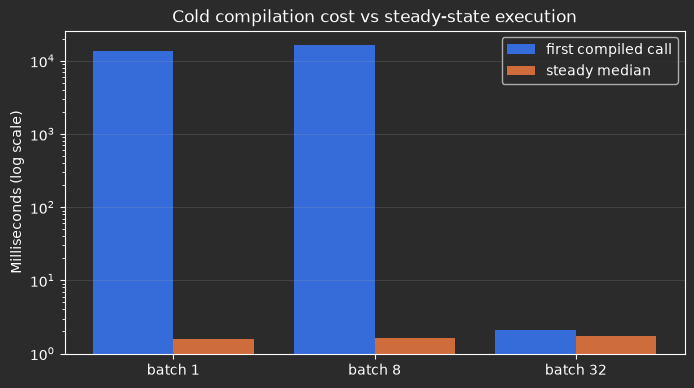

In [5]:
compiled_rows = sorted((row for row in rows if row['configuration'] == 'E'), key=lambda row: int(row['batch_size']))
print(f"{'batch':>5} {'API setup':>12} {'first call':>14} {'steady median':>16}")
for row in compiled_rows:
    print(f"{int(row['batch_size']):>5} {float(row['compile_api_ms']):>10.1f} ms "
          f"{float(row['first_compiled_call_ms']):>12.1f} ms {float(row['median_latency_ms']):>14.3f} ms")

figure, axis = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(compiled_rows))
axis.bar(x - 0.2, [float(row['first_compiled_call_ms']) for row in compiled_rows], width=0.4, label='first compiled call')
axis.bar(x + 0.2, [float(row['median_latency_ms']) for row in compiled_rows], width=0.4, label='steady median')
axis.set_yscale('log')
axis.set_xticks(x, [f"batch {row['batch_size']}" for row in compiled_rows])
axis.set_ylabel('Milliseconds (log scale)')
axis.set_title('Cold compilation cost vs steady-state execution')
axis.legend()
axis.grid(axis='y', alpha=0.25)
plt.show()

In [6]:
for batch in (1, 8, 32):
    eager = next(row for row in rows if row['configuration'] == 'D' and int(row['batch_size']) == batch)
    compiled = next(row for row in rows if row['configuration'] == 'E' and int(row['batch_size']) == batch)
    speedup = float(eager['median_latency_ms']) / float(compiled['median_latency_ms'])
    print(f'Batch {batch:>2}: compiled SDPA is {speedup:.2f}× the eager SDPA steady-state speed')

success = [100.0 * float(batch32[name]['rollout_success_rate']) for name in labels]
print(f"\nRollout success range across configurations: {min(success):.1f}%–{max(success):.1f}%")
print('The speedups did not change the discrete closed-loop outcome on the fixed test scenes.')

Batch  1: compiled SDPA is 1.25× the eager SDPA steady-state speed
Batch  8: compiled SDPA is 1.32× the eager SDPA steady-state speed
Batch 32: compiled SDPA is 1.14× the eager SDPA steady-state speed

Rollout success range across configurations: 21.0%–21.0%
The speedups did not change the discrete closed-loop outcome on the fixed test scenes.


### What this run says

- FP32 reference attention was fastest overall for this very small model.
- SDPA improved BF16 eager execution at batch 32.
- Compilation recovered much of BF16's overhead in steady state, but cold compilation was costly.
- Autocast kept FP32 weights, so weight memory stayed fixed while workspace memory changed.
- Task success—not action MSE alone—remained the final quality check.

These conclusions are hardware- and shape-specific. Re-run the benchmark before applying them to a larger VLA or a deployment GPU.